In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

print("EDA environment ready!")

EDA environment ready!


In [3]:
purchase_transactions = pd.read_csv("/content/purchase_transactions.csv")

In [4]:
total_revenue = purchase_transactions["Revenue"].sum()

total_customers = purchase_transactions["CustomerID"].nunique()

total_orders = purchase_transactions["Invoice"].nunique()

total_products = purchase_transactions["StockCode"].nunique()

invoice_revenue = purchase_transactions.groupby(
    "Invoice"
)["Revenue"].sum()

average_order_value = invoice_revenue.mean()

average_customer_revenue = (
    purchase_transactions.groupby("CustomerID")["Revenue"].sum().mean()
)

print("========== BUSINESS OVERVIEW ==========")

print("Total Revenue:", round(total_revenue, 2))
print("Total Customers:", total_customers)
print("Total Orders:", total_orders)
print("Total Products:", total_products)
print("Average Order Value:", round(average_order_value, 2))
print("Average Revenue per Customer:",
      round(average_customer_revenue, 2))

========== BUSINESS OVERVIEW ==========
Total Revenue: 17374804.27
Total Customers: 5878
Total Orders: 36969
Total Products: 4631
Average Order Value: 469.98
Average Revenue per Customer: 2955.9


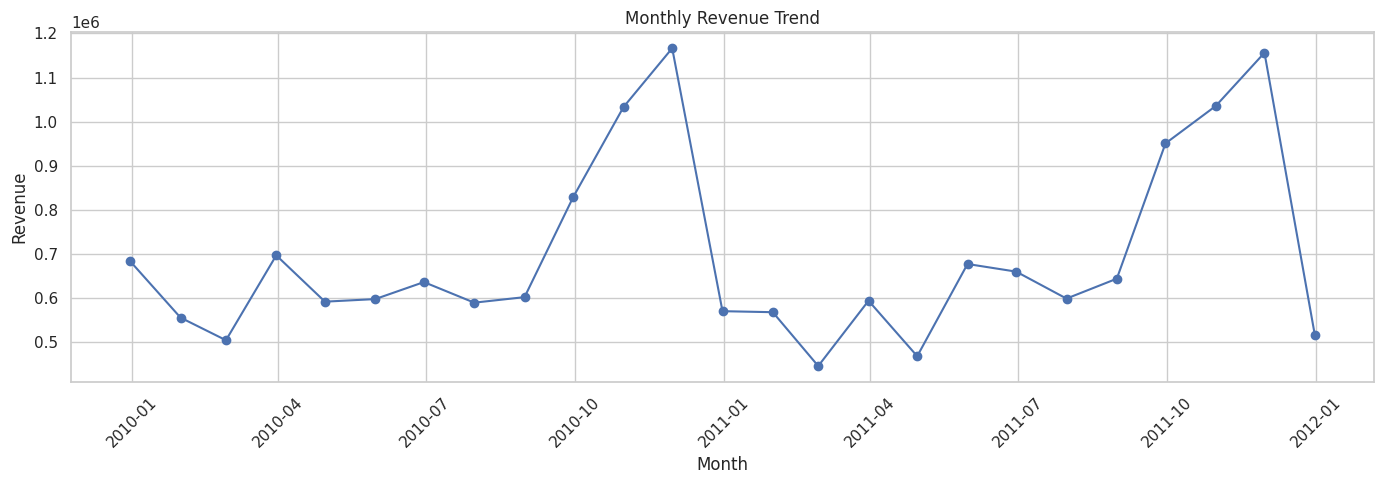

In [6]:
# Monthly revenue
purchase_transactions["InvoiceDate"] = pd.to_datetime(purchase_transactions["InvoiceDate"])

monthly_revenue = (
    purchase_transactions
    .set_index("InvoiceDate")
    .resample("ME")["Revenue"]
    .sum()
)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

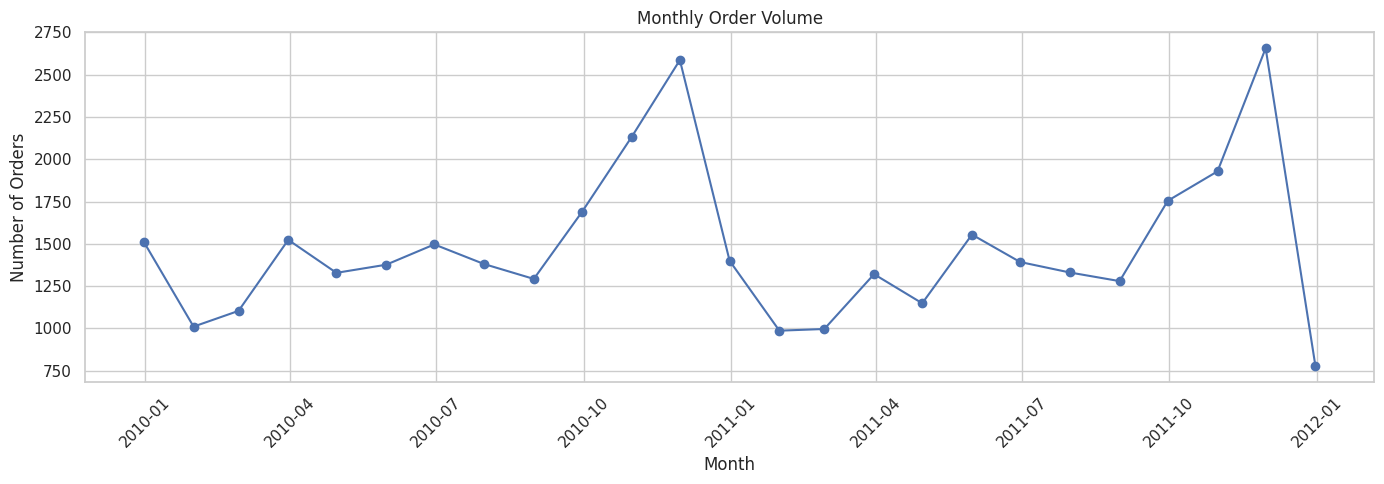

In [7]:
# monthly orders number
monthly_orders = (
    purchase_transactions
    .set_index("InvoiceDate")
    .resample("ME")["Invoice"]
    .nunique()
)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_orders.index,
    monthly_orders.values,
    marker="o"
)

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Revenue
Year,
2009,683504.010
2010,8374496.094
2011,8316804.164


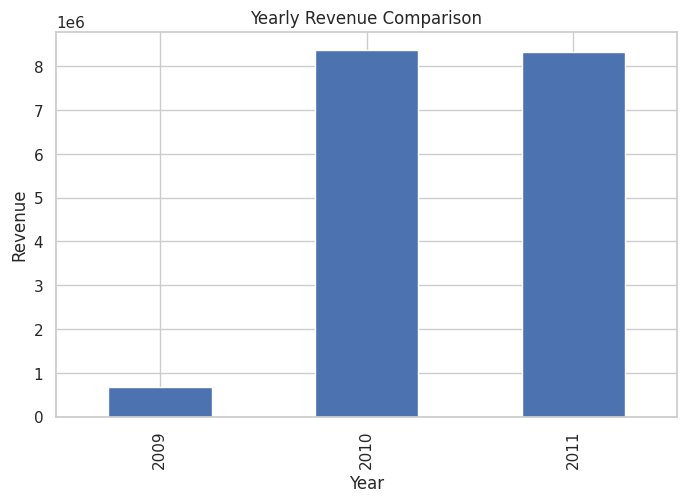

In [8]:
purchase_transactions["Year"] = (
    purchase_transactions["InvoiceDate"].dt.year
)

yearly_revenue = purchase_transactions.groupby(
    "Year"
)["Revenue"].sum()

display(yearly_revenue)

yearly_revenue.plot(
    kind="bar",
    figsize=(8, 5),
    title="Yearly Revenue Comparison"
)

plt.ylabel("Revenue")
plt.show()

In [11]:
customer_summary = purchase_transactions.groupby(
    "CustomerID"
).agg(
    TotalRevenue=("Revenue", "sum"),
    TotalOrders=("Invoice", "nunique"),
    TotalQuantity=("Quantity", "sum"),
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max")
).reset_index()

In [12]:
invoice_values = (
    purchase_transactions
    .groupby(["CustomerID", "Invoice"])["Revenue"]
    .sum()
    .reset_index(name="InvoiceRevenue")
)

customer_aov = (
    invoice_values
    .groupby("CustomerID")["InvoiceRevenue"]
    .mean()
    .reset_index(name="AverageOrderValue")
)

customer_summary = customer_summary.merge(
    customer_aov,
    on="CustomerID",
    how="left"
)

display(customer_summary.head())

print("Customer summary shape:", customer_summary.shape)

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,FirstPurchase,LastPurchase,AverageOrderValue
0,12346.0,77556.46,12,74285,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333
1,12347.0,4921.53,8,2967,2010-10-31 14:20:00,2011-12-07 15:52:00,615.191250
2,12348.0,2019.40,5,2714,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000
3,12349.0,4428.69,4,1624,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500
4,12350.0,334.40,1,197,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000


Customer summary shape: (5878, 7)


,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,FirstPurchase,LastPurchase,AverageOrderValue
5692,18102.0,580987.04,145,181645,2009-12-01 09:24:00,2011-12-09 11:50:00,4006.807172
2277,14646.0,528602.52,151,367193,2009-12-02 16:52:00,2011-12-08 12:12:00,3500.678940
1789,14156.0,313437.62,156,164325,2009-12-01 12:30:00,2011-11-30 10:54:00,2009.215513
2538,14911.0,291420.81,398,147972,2009-12-01 11:41:00,2011-12-08 15:54:00,732.213090
5050,17450.0,244784.25,51,83914,2010-09-27 16:59:00,2011-12-01 13:29:00,4799.691176
1331,13694.0,195640.69,143,188201,2009-12-04 15:26:00,2011-12-06 09:32:00,1368.116713
5109,17511.0,172132.87,60,117174,2009-12-02 10:52:00,2011-12-07 10:12:00,2868.881167
4061,16446.0,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00,84236.250000
4295,16684.0,147142.77,55,104810,2009-12-07 12:56:00,2011-12-05 14:06:00,2675.323091
68,12415.0,144458.37,28,91447,2010-06-30 08:30:00,2011-11-15 14:22:00,5159.227500


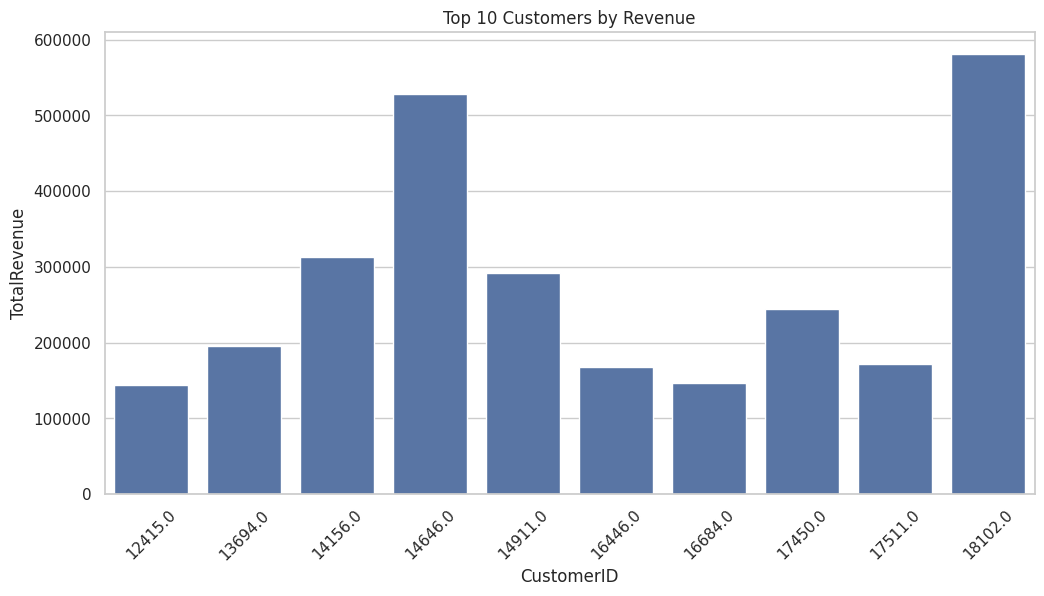

In [14]:
# top customers
top_customers = customer_summary.sort_values(
    by="TotalRevenue",
    ascending=False
).head(10)

display(top_customers)
#visually display

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers,
    x="CustomerID",
    y="TotalRevenue"
)

plt.title("Top 10 Customers by Revenue")
plt.xticks(rotation=45)
plt.show()

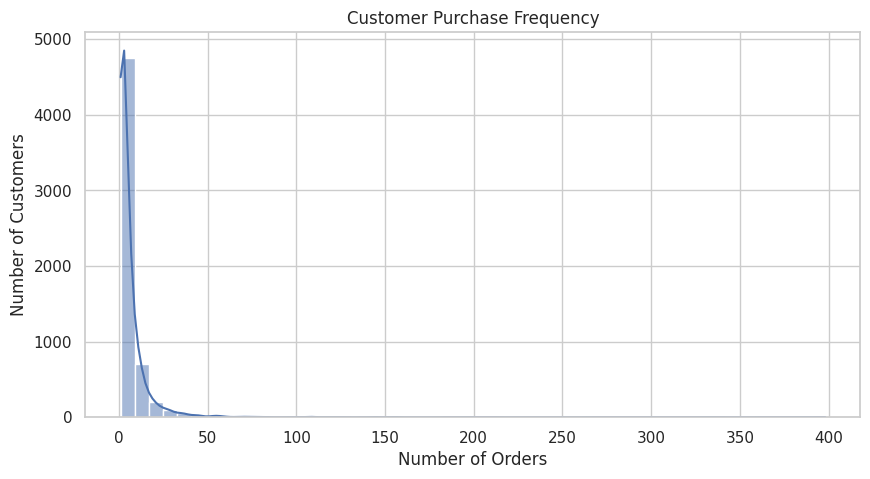

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    customer_summary["TotalOrders"],
    bins=50,
    kde=True
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.show()

In [16]:
display(customer_summary["TotalOrders"].describe())

,TotalOrders
count,5878.000000
mean,6.289384
std,13.009406
min,1.000000
25%,1.000000
50%,3.000000
75%,7.000000
max,398.000000


,Description,TotalRevenue,TotalQuantity,TotalOrders
0,REGENCY CAKESTAND 3 TIER,277656.25,24124,3317
1,WHITE HANGING HEART T-LIGHT HOLDER,247048.01,91757,4888
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3,Manual,151777.67,9384,620
4,JUMBO BAG RED RETROSPOT,134307.44,74224,2612
5,POSTAGE,124648.04,5235,1803
6,ASSORTED COLOUR BIRD ORNAMENT,124351.86,78234,2652
7,PARTY BUNTING,103283.38,23460,2077
8,MEDIUM CERAMIC TOP STORAGE JAR,81416.73,77916,195
9,PAPER CHAIN KIT 50'S CHRISTMAS,76598.18,28380,1691


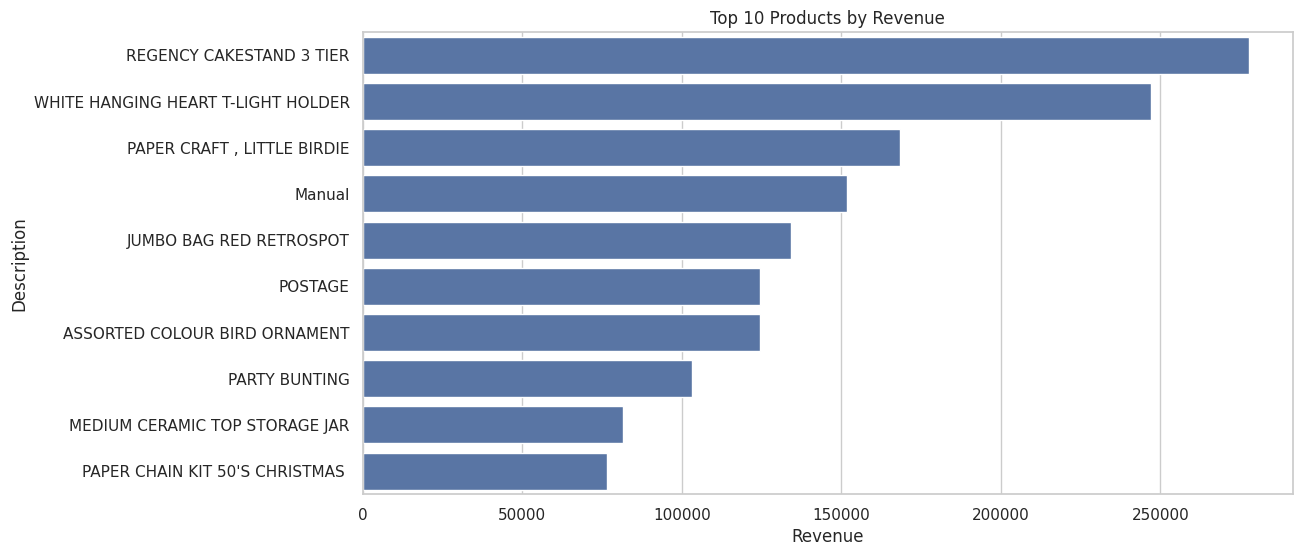

In [18]:
product_analysis = (
    purchase_transactions
    .groupby("Description")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        TotalOrders=("Invoice", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
    .head(10)
    .reset_index()
)

display(product_analysis)


#visual display
plt.figure(figsize=(12, 6))

sns.barplot(
    data=product_analysis,
    x="TotalRevenue",
    y="Description"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.show()

,Country,TotalRevenue,TotalCustomers,TotalOrders
0,United Kingdom,1.438923e+07,5350,33541
1,EIRE,6.165705e+05,5,567
2,Netherlands,5.540381e+05,22,228
3,Germany,4.250197e+05,107,789
4,France,3.487690e+05,95,614
5,Australia,1.692835e+05,15,95
6,Spain,1.083325e+05,41,154
7,Switzerland,1.000619e+05,22,90
8,Sweden,9.151582e+04,19,104
9,Denmark,6.858069e+04,12,43


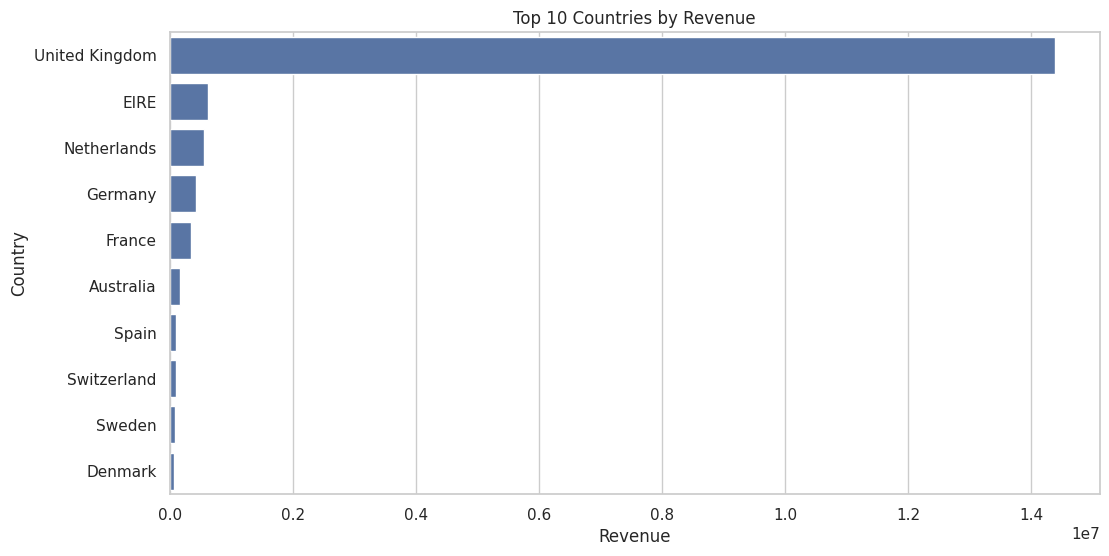

In [20]:
country_analysis = (
    purchase_transactions
    .groupby("Country")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalCustomers=("CustomerID", "nunique"),
        TotalOrders=("Invoice", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
    .reset_index()
)

display(country_analysis.head(15))

#visual
top_countries = country_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x="TotalRevenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.show()

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,FirstPurchase,LastPurchase,AverageOrderValue,Recency
0,12346.0,77556.46,12,74285,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,326
1,12347.0,4921.53,8,2967,2010-10-31 14:20:00,2011-12-07 15:52:00,615.191250,2
2,12348.0,2019.40,5,2714,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,75
3,12349.0,4428.69,4,1624,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,19
4,12350.0,334.40,1,197,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,310


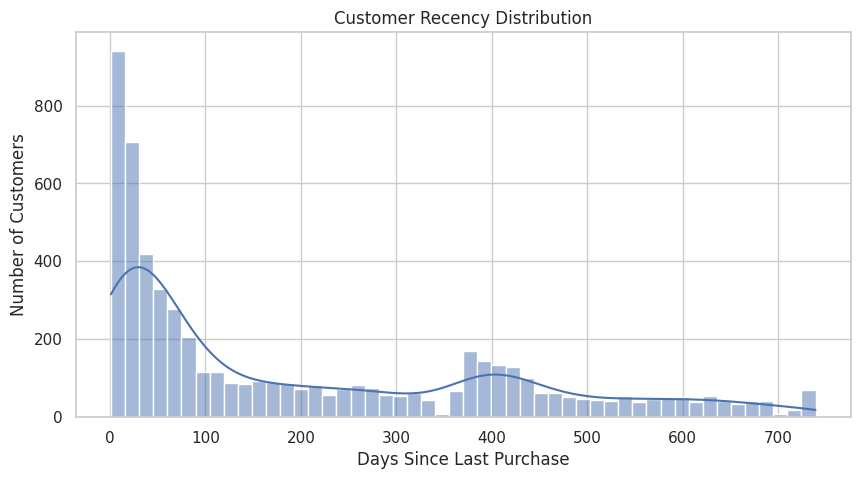

In [22]:
analysis_date = (
    purchase_transactions["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

customer_summary["Recency"] = (
    analysis_date - customer_summary["LastPurchase"]
).dt.days

display(customer_summary.head())


plt.figure(figsize=(10, 5))

sns.histplot(
    customer_summary["Recency"],
    bins=50,
    kde=True
)

plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.show()

One-time customers: 1623
Repeat customers: 4255
Repeat customer percentage: 72.39 %


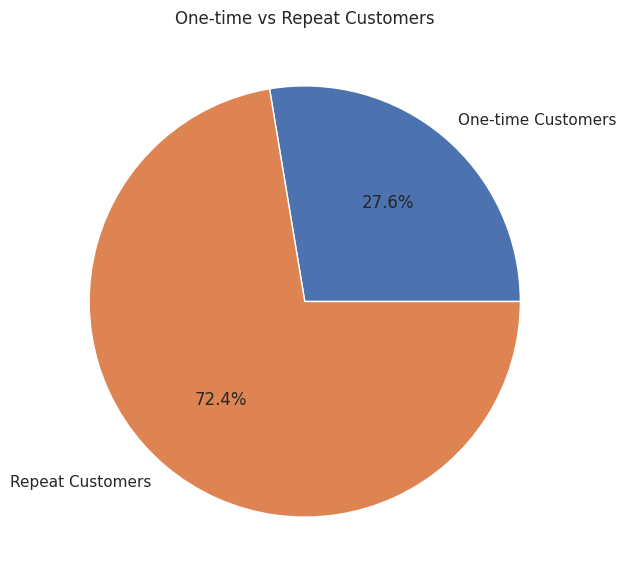

In [24]:
repeat_customers = (
    customer_summary["TotalOrders"] > 1
).sum()

one_time_customers = (
    customer_summary["TotalOrders"] == 1
).sum()

total_customers = len(customer_summary)

print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)

print(
    "Repeat customer percentage:",
    round(repeat_customers / total_customers * 100, 2),
    "%"
)

#visually
customer_types = pd.Series({
    "One-time Customers": one_time_customers,
    "Repeat Customers": repeat_customers
})

customer_types.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    title="One-time vs Repeat Customers"
)

plt.ylabel("")
plt.show()

In [27]:
import os

# Define the missing DATA_PATH variable
DATA_PATH = "/content"

os.makedirs(DATA_PATH, exist_ok=True)

customer_summary.to_csv(
    DATA_PATH + "/customer_summary.csv",
    index=False
)

country_analysis.to_csv(
    DATA_PATH + "/country_analysis.csv",
    index=False
)

product_analysis.to_csv(
    DATA_PATH + "/top_products.csv",
    index=False
)

print("EDA outputs saved successfully!")

EDA outputs saved successfully!
